<div style="font-family:Times New Roman;font-size:14pt;color:black"><b>Лабораторна робота 8</b><br>Нейронна мережа Keras для Fashion MNIST<br>Виконав Шиндир Олексій<br>4 курс, 10 група</div>

<a href="https://colab.research.google.com/github/raysewww-lang/mashynne-navchannia/blob/main/%D0%A8%D0%B8%D0%BD%D0%B4%D0%B8%D1%80_%D0%BF%D1%80_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Відкрити в Colab"/></a>

In [1]:
# Підготовка бібліотек і даних. Дані автоматично завантажуються з GitHub; резервний спосіб — data.zip.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
np.random.seed(25)
plt.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','DejaVu Serif'],'font.size':14,'figure.figsize':(9,5)})
pd.set_option('display.max_columns',40)

def data_path(name):
    for folder in [Path('data'),Path('.'),Path('/content/data'),Path('/content')]:
        p=folder/name
        if p.exists():
            return p
    import zipfile, io
    from urllib.request import urlopen
    try:
        url='https://raw.githubusercontent.com/raysewww-lang/mashynne-navchannia/main/data.zip'
        with urlopen(url, timeout=60) as response:
            content=response.read()
        Path('data').mkdir(exist_ok=True)
        with zipfile.ZipFile(io.BytesIO(content)) as z:
            for member in z.namelist():
                if not member.endswith('/'):
                    (Path('data')/Path(member).name).write_bytes(z.read(member))
        if (Path('data')/name).exists():
            return Path('data')/name
    except Exception as error:
        print('Автоматичне завантаження недоступне:',error)
    from google.colab import files
    import zipfile, io
    print('Завантажте data.zip або файл',name)
    uploaded=files.upload()
    Path('data').mkdir(exist_ok=True)
    for fname,content in uploaded.items():
        if fname.endswith('.zip'):
            with zipfile.ZipFile(io.BytesIO(content)) as z:
                for member in z.namelist():
                    if not member.endswith('/'):
                        (Path('data')/Path(member).name).write_bytes(z.read(member))
        else:
            (Path('data')/Path(fname).name).write_bytes(content)
    p=Path('data')/name
    if not p.exists():
        raise FileNotFoundError(name)
    return p

In [2]:
# Підготовка TensorFlow, функцій побудови графіків та оцінки.
import os
os.environ['TF_CPP_MIN_LOG_LEVEL']='2'
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.keras.utils.set_random_seed(25)
try:
    tf.config.threading.set_inter_op_parallelism_threads(2)
    tf.config.threading.set_intra_op_parallelism_threads(2)
except RuntimeError:
    pass
def callbacks():
    return [keras.callbacks.EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True),keras.callbacks.ReduceLROnPlateau(monitor='val_loss',factor=0.5,patience=2,min_lr=1e-6)]
def curves(history,title):
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for ax,metric in zip(axes,['loss','accuracy']):
        ax.plot(history.history[metric],label='Train')
        ax.plot(history.history['val_'+metric],label='Validation')
        if 'test_'+metric in history.history:
            ax.plot(history.history['test_'+metric],label='Test')
        ax.set(xlabel='Епоха',ylabel=metric,title=title);ax.legend()
    plt.tight_layout();plt.show()
def recognition(model,x,y,names):
    p=model.predict(x,verbose=0).argmax(axis=1)
    print(classification_report(y,p,target_names=names,zero_division=0))
    fig,axes=plt.subplots(2,5,figsize=(15,6))
    for i,ax in enumerate(axes.flat):
        ax.imshow(x[i].squeeze(),cmap='gray');ax.axis('off')
        ax.set_title('Іст.: '+names[int(y[i])]+'\nПр.: '+names[int(p[i])],fontsize=11)
    plt.tight_layout();plt.show()
    return p

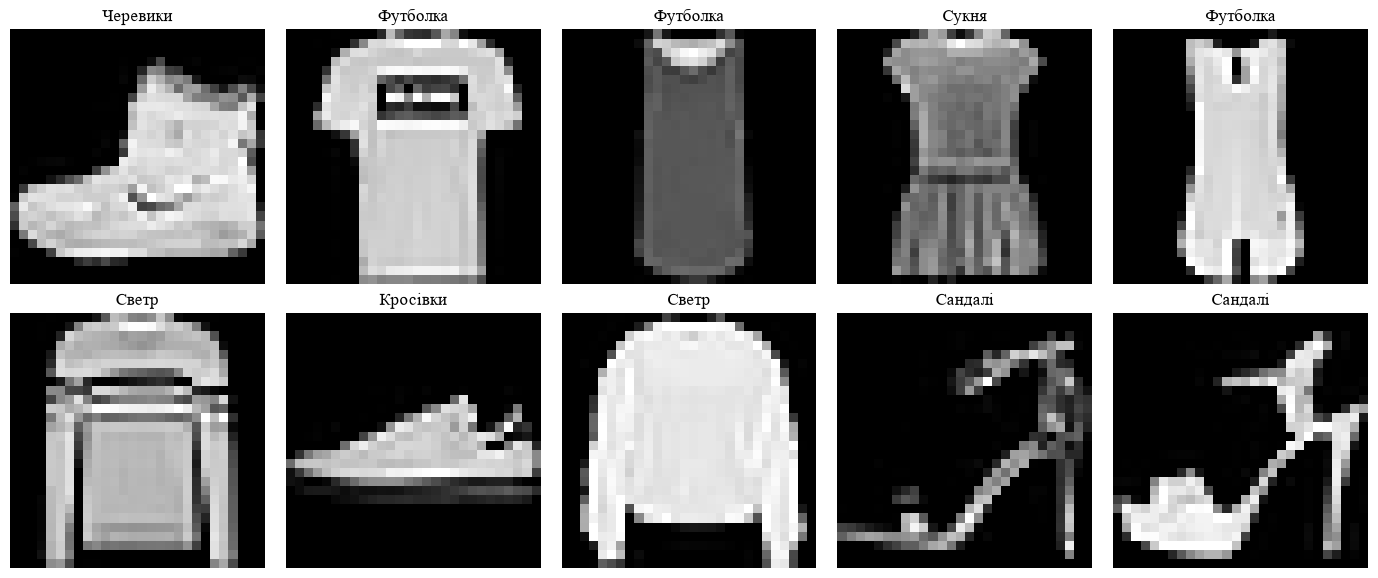

Train, validation, test: (48000, 28, 28) (12000, 28, 28) (10000, 28, 28)


In [3]:
# Завдання 1. Пункти 1–3: завантажити Fashion MNIST, показати 10 зображень, підготувати дані.
(x_train_full,y_train_full),(x_test,y_test)=keras.datasets.fashion_mnist.load_data()
names=['Футболка','Штани','Светр','Сукня','Пальто','Сандалі','Сорочка','Кросівки','Сумка','Черевики']
fig,axes=plt.subplots(2,5,figsize=(14,6))
for i,ax in enumerate(axes.flat):
    ax.imshow(x_train_full[i],cmap='gray');ax.set_title(names[y_train_full[i]],fontsize=12);ax.axis('off')
plt.tight_layout();plt.show()
x_train_full=x_train_full.astype('float32')/255
x_test=x_test.astype('float32')/255
x_train,x_val,y_train,y_val=train_test_split(x_train_full,y_train_full,test_size=0.2,stratify=y_train_full,random_state=25)
print('Train, validation, test:',x_train.shape,x_val.shape,x_test.shape)
class TestCurve(keras.callbacks.Callback):
    def __init__(self,x,y):
        super().__init__();self.x=x;self.y=y;self.loss=[];self.acc=[]
    def on_epoch_end(self,epoch,logs=None):
        loss,acc=self.model.evaluate(self.x,self.y,verbose=0)
        self.loss.append(loss);self.acc.append(acc)

In [4]:
# Завдання 1. Пункти 3–5: багатошарова мережа, early stopping, зменшення learning rate, summary та навчання.
model=keras.Sequential([layers.Input((28,28)),layers.Flatten(),layers.Dense(128,activation='relu'),layers.Dropout(0.2),layers.Dense(64,activation='relu'),layers.Dense(10,activation='softmax')])
model.compile(optimizer=keras.optimizers.Adam(1e-3),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
model.summary()
test_curve=TestCurve(x_test,y_test)
history=model.fit(x_train,y_train,validation_data=(x_val,y_val),epochs=15,batch_size=128,callbacks=callbacks()+[test_curve],verbose=2)
history.history['test_loss']=test_curve.loss;history.history['test_accuracy']=test_curve.acc

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15


... (25 outputs left out)

Epoch 14/15


375/375 - 1s - 3ms/step - accuracy: 0.9099 - loss: 0.2418 - val_accuracy: 0.8923 - val_loss: 0.3057 - learning_rate: 2.5000e-04


Epoch 15/15


375/375 - 1s - 3ms/step - accuracy: 0.9116 - loss: 0.2367 - val_accuracy: 0.8925 - val_loss: 0.3090 - learning_rate: 2.5000e-04


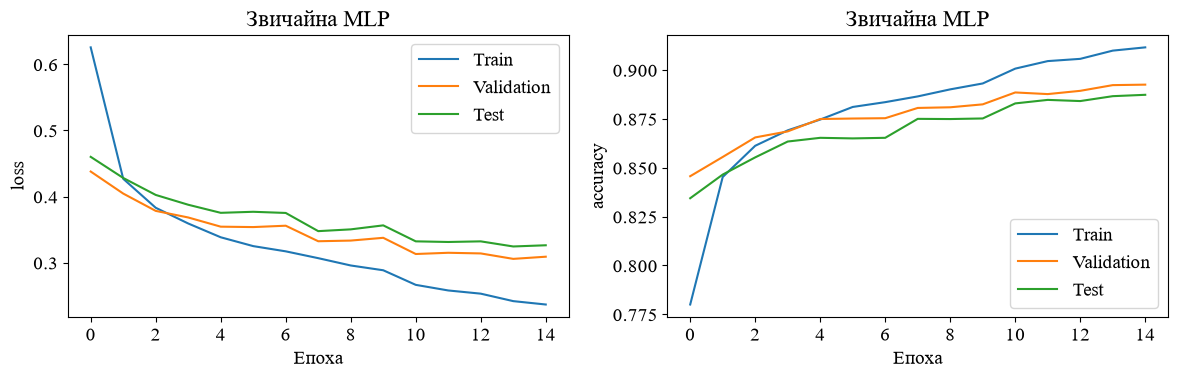

Test loss: 0.32447293400764465 Test accuracy: 0.8866000175476074
Test на графіках наведено за умовою методички. Test не використовується для зупинки, зміни learning rate чи вибору гіперпараметрів; ці рішення залежать тільки від validation.


              precision    recall  f1-score   support

    Футболка       0.86      0.83      0.84      1000
       Штани       0.99      0.97      0.98      1000
       Светр       0.78      0.82      0.80      1000
       Сукня       0.88      0.90      0.89      1000
      Пальто       0.80      0.82      0.81      1000
     Сандалі       0.97      0.97      0.97      1000
     Сорочка       0.71      0.68      0.69      1000
    Кросівки       0.94      0.96      0.95      1000
       Сумка       0.97      0.97      0.97      1000
    Черевики       0.97      0.95      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



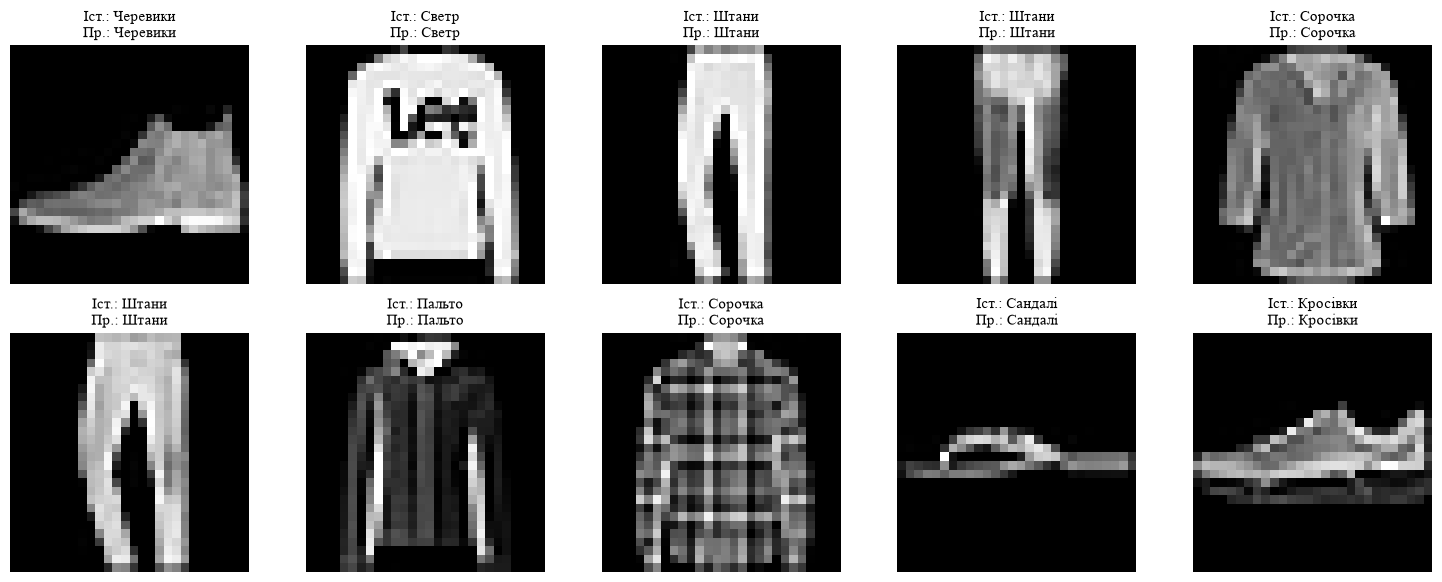

In [5]:
# Завдання 1. Пункти 7–9: графіки, тестова оцінка, classification report, справжні й прогнозовані класи.
curves(history,'Звичайна MLP')
test_loss,test_acc=model.evaluate(x_test,y_test,verbose=0)
print('Test loss:',test_loss,'Test accuracy:',test_acc)
print('Test на графіках наведено за умовою методички. Test не використовується для зупинки, зміни learning rate чи вибору гіперпараметрів; ці рішення залежать тільки від validation.')
pred=recognition(model,x_test,y_test,names)

In [6]:
# Завдання 1. Пункт 6: зберегти модель. У Colab — на Google Drive після підключення диска; локально — у models.
import importlib.util
if importlib.util.find_spec('google.colab') is not None:
    from google.colab import drive
    drive.mount('/content/drive')
    model_dir=Path('/content/drive/MyDrive/Машинне навчання')
else:
    model_dir=Path('models')
model_dir.mkdir(parents=True,exist_ok=True)
model.save(model_dir/'Шиндир_пр_8_mlp.keras')
print('Збережено:',model_dir/'Шиндир_пр_8_mlp.keras')

Збережено: models\Шиндир_пр_8_mlp.keras


In [7]:
# Завдання 2. Keras Tuner: підібрати гіперпараметри аналогічної мережі без використання тестових даних.
import importlib.util,subprocess,sys
if importlib.util.find_spec('keras_tuner') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','keras-tuner'])
if importlib.util.find_spec('tensorboard') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','tensorboard'])
import keras_tuner as kt
def build_model(hp):
    m=keras.Sequential([layers.Input((28,28)),layers.Flatten(),layers.Dense(hp.Choice('units',[64,128,256]),activation='relu'),layers.Dropout(hp.Choice('dropout',[0.1,0.3])),layers.Dense(64,activation='relu'),layers.Dense(10,activation='softmax')])
    m.compile(optimizer=keras.optimizers.Adam(hp.Choice('learning_rate',[1e-3,3e-4])),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    return m
tuner_dir=Path('tuner').resolve()
tuner_dir.mkdir(exist_ok=True)
if os.name=='nt':
    import ctypes
    buffer=ctypes.create_unicode_buffer(32768)
    if ctypes.windll.kernel32.GetShortPathNameW(str(tuner_dir),buffer,len(buffer)):
        tuner_dir=Path(buffer.value)
tuner=kt.RandomSearch(build_model,objective='val_accuracy',max_trials=3,seed=25,directory=str(tuner_dir),project_name='shyndyr8',overwrite=True)
tuner.search(x_train,y_train,validation_data=(x_val,y_val),epochs=6,batch_size=128,callbacks=callbacks(),verbose=2)
best_hp=tuner.get_best_hyperparameters(1)[0]
print('Найкращі гіперпараметри:',best_hp.values)
tuned=build_model(best_hp)
tuned.summary()
tuned_test_curve=TestCurve(x_test,y_test)
tuned_history=tuned.fit(x_train,y_train,validation_data=(x_val,y_val),epochs=15,batch_size=128,callbacks=callbacks()+[tuned_test_curve],verbose=2)
tuned_history.history['test_loss']=tuned_test_curve.loss;tuned_history.history['test_accuracy']=tuned_test_curve.acc

Trial 3 Complete [00h 00m 05s]
val_accuracy: 0.862583339214325

Best val_accuracy So Far: 0.8691666722297668
Total elapsed time: 00h 00m 16s
Найкращі гіперпараметри: {'units': 128, 'dropout': 0.3, 'learning_rate': 0.0003}


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

... (26 outputs left out)

Epoch 14/15


375/375 - 1s - 3ms/step - accuracy: 0.8866 - loss: 0.3101 - val_accuracy: 0.8855 - val_loss: 0.3228 - learning_rate: 3.0000e-04


Epoch 15/15


375/375 - 1s - 3ms/step - accuracy: 0.8899 - loss: 0.3042 - val_accuracy: 0.8852 - val_loss: 0.3227 - learning_rate: 3.0000e-04


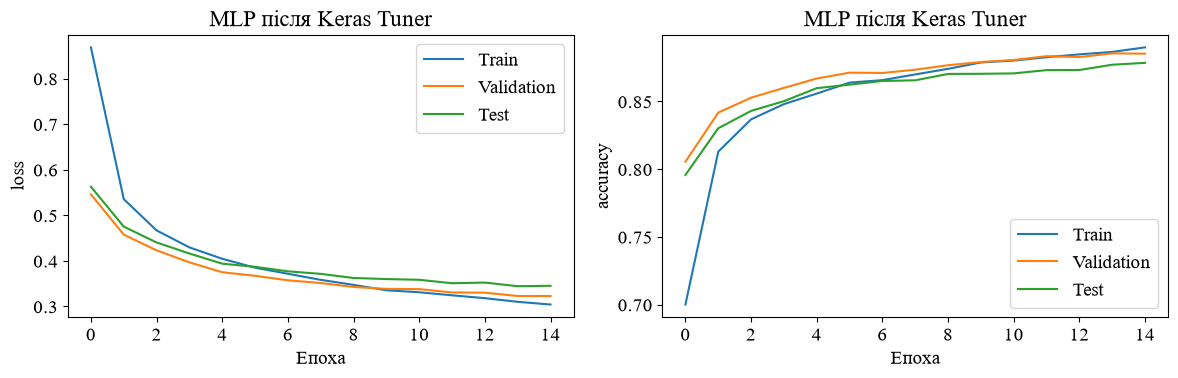

              precision    recall  f1-score   support

    Футболка       0.81      0.86      0.83      1000
       Штани       0.99      0.96      0.98      1000
       Светр       0.76      0.81      0.79      1000
       Сукня       0.86      0.90      0.88      1000
      Пальто       0.77      0.83      0.80      1000
     Сандалі       0.96      0.96      0.96      1000
     Сорочка       0.75      0.58      0.65      1000
    Кросівки       0.93      0.96      0.94      1000
       Сумка       0.97      0.98      0.97      1000
    Черевики       0.97      0.95      0.96      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



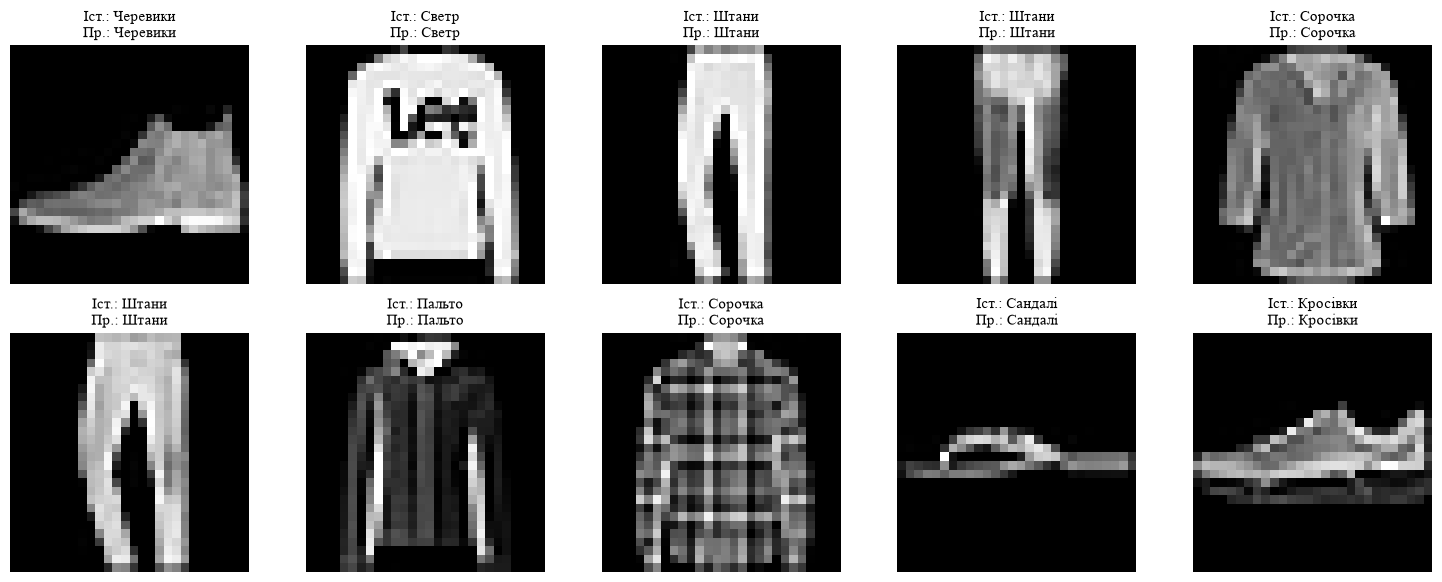

,Модель,Test accuracy,Test loss
0,MLP,0.8866,0.324473
1,Keras Tuner,0.8785,0.345247


Різниця точності Tuner - MLP: -0.008100032806396484
Різниця loss Tuner - MLP: 0.02077430486679077


In [8]:
# Завдання 2. Оцінити підібрану модель, порівняти точність і функцію втрат, графіки та розпізнавання.
curves(tuned_history,'MLP після Keras Tuner')
tuned_loss,tuned_acc=tuned.evaluate(x_test,y_test,verbose=0)
recognition(tuned,x_test,y_test,names)
comparison=pd.DataFrame({'Модель':['MLP','Keras Tuner'],'Test accuracy':[test_acc,tuned_acc],'Test loss':[test_loss,tuned_loss]})
display(comparison)
print('Різниця точності Tuner - MLP:',tuned_acc-test_acc)
print('Різниця loss Tuner - MLP:',tuned_loss-test_loss)
tuned.save(model_dir/'Шиндир_пр_8_tuned.keras')

In [9]:
# Висновок. Побудовано багатошарову мережу для Fashion MNIST та виконано пошук гіперпараметрів Keras Tuner. Використано ранню зупинку та зменшення швидкості навчання за validation. На графіках наведено train, validation і test; test використано тільки для звітування, без вибору гіперпараметрів чи зупинки навчання. Порівняння accuracy і loss наведено в таблиці; невеликий пошук не гарантує покращення. Моделі збережено у шлях, виведений вище.